# ICT304 Assignment
## FridgeChef: YOLO11s + RF-DETR Small ensemble
**Team:** Parth Kotak · Wadiqa Baig · Syeda Masooma Zehra Naqvi

We compare two trained detectors and their combined predictions on the same images. An **ensemble** combines model outputs. **Weighted Boxes Fusion (WBF)** merges overlapping boxes for the same ingredient.

The saved outputs show the completed final test. The default configuration repeats evaluation from the supplied weights and frozen validation choices, without retraining. Saved timings describe the recorded GPU; new runs record their own runtime.

## 1. Run in Google Colab

1. Keep the complete submitted **Code** folder together. Upload it inside **MyDrive/Group Assignment Submission**, or **MyDrive/ICT304/Group Assignment Submission**. Include both model folders and the dataset.
2. Open this notebook in Colab. Choose **Runtime → Change runtime type → T4 GPU**.
3. Leave `code_root=None` for either location above. Otherwise, set it to the full path of **Code**. The checkpoint and settings paths are relative to that folder.
4. Keep `mode="final-test"`, `final_test_enabled=True` and `settings_frozen=True`. This reuses the supplied validation choices and does not train or search for new settings.
5. Choose **Runtime → Run all** and allow Drive access. If Colab requests a restart after installation, restart and run all again.
6. If the 15-minute prediction budget is reached, rerun **Collect component predictions** and the cells below it. Compatible saved predictions are reused.
7. Read the comparison table and demonstration. New files are under **Code/lecturer_runs/ensemble**. Save your executed notebook separately.

Read the saved outputs without running anything. Local runs perform preparation only. To repeat validation development on Colab, set `mode="validation"`, `final_test_enabled=False` and `settings_frozen=False`; never select settings from test scores.

## 2. Configuration

Relative paths start at the submitted Code folder. `code_root` provides an explicit override.

A **checkpoint** is a saved trained model. Use YOLO11s **best.pt** and RF-DETR's full-run **native/checkpoint_best_total.pth**, or **checkpoint_best_regular.pth**. Smoke checkpoints are excluded.

The initial experiment tests three model-weight ratios and two box-overlap thresholds. Weights control each detector's influence; they do not make confidence scores calibrated probabilities.

In [ ]:
# Keep paths and experiment settings together.
CONFIG = {
    "mode": "final-test",
    "code_root": None,
    "copy_dataset_to_colab": True,
    "dataset_path": "Fridge_Combined_YOLO",
    "dataset_override": None,
    "drive_output_root": "lecturer_runs/ensemble",
    "yolo_checkpoint": "Fridge_YOLO/best.pt",
    "rfdetr_checkpoint": "FridgeChef_RFDETR/training_runs/rfdetr/20261002T212750Z_1bb5fe/native/checkpoint_best_total.pth",
    "rfdetr_run_root": "FridgeChef_RFDETR/training_runs/rfdetr",
    "ultralytics_version": "8.4.171",
    "rfdetr_version": "1.11.1",
    "ensemble_boxes_version": "1.0.9",
    "seed": 304,
    "device": "cuda",
    "yolo_image_size": 640,
    "rfdetr_image_size": 512,
    "yolo_nms_iou": 0.7,
    "prediction_floor": 0.001,
    "max_detections": 300,
    "match_iou": 0.5,
    "fusion_weights": [[1, 1], [1, 2], [2, 1]],
    "fusion_iou_candidates": [0.5, 0.6],
    "fusion_confidence_type": "box_and_model_avg",
    "threshold_candidates": [0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5, 0.6, 0.7],
    "minimum_ensemble_gain": 0.005,
    "prediction_budget_minutes": 15,
    "benchmark_images": 10,
    "geometry_sample_images": 300,
    # Leave the test split locked during validation.
    "final_test_enabled": True,
    "settings_frozen": True,
    "frozen_settings_path": "FridgeChef_Ensemble/evaluation_results/20261002T234626Z_a4f9fe/frozen_validation_settings.json",
    "demo_image": None,
}
assert CONFIG['mode'] in {'preparation', 'validation', 'final-test'}
assert CONFIG['device'] == 'cuda' and CONFIG['max_detections'] == 300
assert 0 < CONFIG['prediction_floor'] < min(CONFIG['threshold_candidates'])
assert 1 <= CONFIG['prediction_budget_minutes'] <= 60
assert 0 <= CONFIG['benchmark_images'] <= 20
assert len(CONFIG['fusion_weights']) * len(CONFIG['fusion_iou_candidates']) <= 6
assert all(len(w) == 2 and all(v > 0 for v in w) for w in CONFIG['fusion_weights'])
assert all(0 < value < 1 for value in CONFIG['fusion_iou_candidates'])
assert CONFIG['fusion_confidence_type'] == 'box_and_model_avg'
assert CONFIG['final_test_enabled'] == (CONFIG['mode'] == 'final-test')
if CONFIG['final_test_enabled']:
    assert CONFIG['settings_frozen'] and CONFIG['frozen_settings_path']

## 3. Environment and dataset

Colab installs the specified package versions and keeps its existing PyTorch setup. Both detectors use full precision (FP32), one image at a time, on the GPU. Local runs perform preparation only.

Fixed seeds help repeatability but do not guarantee identical GPU results. CUDA must be available before prediction starts.

In [ ]:
import os
import sys
import json
import time
import hashlib
import uuid
import tempfile
import shutil
import subprocess
import importlib.metadata
from pathlib import Path
from datetime import datetime, timezone

os.environ.setdefault('MPLCONFIGDIR', str(Path(tempfile.gettempdir()) / 'fridgechef_ensemble_matplotlib'))
IN_COLAB = 'google.colab' in sys.modules or bool(os.environ.get('COLAB_RELEASE_TAG'))
EFFECTIVE_MODE = CONFIG['mode'] if IN_COLAB else 'preparation'
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    # Keep the PyTorch versions supplied by Colab.
    constraints = Path('/content/ensemble_torch_constraints.txt')
    constraints.write_text('\n'.join(name + '==' + importlib.metadata.version(name) for name in ['torch', 'torchvision']))
    pinned = {'ultralytics': CONFIG['ultralytics_version'], 'rfdetr': CONFIG['rfdetr_version'],
              'ensemble-boxes': CONFIG['ensemble_boxes_version'], 'pycocotools': '2.0.11'}
    requirements = []
    for name, version in pinned.items():
        try:
            installed = importlib.metadata.version(name)
        except importlib.metadata.PackageNotFoundError:
            installed = None
        if installed != version:
            requirements.append(name + '==' + version)
    if requirements:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-c', str(constraints), *requirements], check=True)
print('Mode:', EFFECTIVE_MODE, '| interpreter:', sys.executable)


PATH_FIELDS = ["dataset_path", "dataset_override", "drive_output_root", "yolo_checkpoint",
               "rfdetr_checkpoint", "rfdetr_run_root", "frozen_settings_path", "demo_image"]

def resolve_code_root(override=None):
    """Find the submitted Code folder, or validate an explicitly supplied folder."""
    required = ('Fridge_Combined_YOLO', 'FridgeChef_RFDETR', 'Fridge_YOLO')
    def is_code_folder(path):
        return all((path / name).is_dir() for name in required)
    if override:
        chosen = Path(override).expanduser().resolve()
        if not is_code_folder(chosen):
            raise FileNotFoundError(f'code_root must contain the submitted dataset and model folders: {chosen}')
        return chosen
    candidates = []
    for folder in [Path.cwd(), *Path.cwd().parents]:
        candidates.extend([folder, folder / 'Code', folder / 'Group Assignment Submission' / 'Code'])
    candidates.extend([
        Path('/content/drive/MyDrive/Group Assignment Submission/Code'),
        Path('/content/drive/MyDrive/ICT304/Group Assignment Submission/Code'),
    ])
    for candidate in dict.fromkeys(candidates):
        if is_code_folder(candidate):
            return candidate.resolve()
    raise FileNotFoundError('Set CONFIG["code_root"] to the uploaded Code folder, then rerun setup.')


def submission_path(value):
    """Resolve a configured relative path from Code, while allowing an absolute override."""
    if value is None:
        return None
    path = Path(value).expanduser()
    return path.resolve() if path.is_absolute() else (CODE_ROOT / path).resolve()


CODE_ROOT = resolve_code_root(CONFIG['code_root'])
# Resolve every runtime path from the same submission folder.
for name in PATH_FIELDS:
    if CONFIG.get(name) is not None:
        CONFIG[name] = str(submission_path(CONFIG[name]))
print('Submission Code folder:', CODE_ROOT)

Mounted at /content/drive
Mode: final-test | interpreter: /usr/bin/python3


In [ ]:
import zipfile
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import yaml
from PIL import Image
from IPython.display import display, Markdown
from tqdm.auto import tqdm


# Read the supplied dataset; never rebuild or change its reviewed labels.
DATASET_SOURCE = Path(CONFIG['dataset_override'] or CONFIG['dataset_path'])
if not (DATASET_SOURCE / 'metadata/export_registry_v2.json').is_file():
    raise FileNotFoundError(f'The complete submitted dataset is missing: {DATASET_SOURCE}')
DATASET_ROOT = DATASET_SOURCE
if IN_COLAB and CONFIG['copy_dataset_to_colab'] and str(DATASET_SOURCE).startswith('/content/drive/'):
    # Copy once to local Colab storage to avoid thousands of slow Drive reads.
    provenance_hash = hashlib.sha256((DATASET_SOURCE / 'metadata/image_provenance.csv').read_bytes()).hexdigest()
    cache_parent = Path('/content/fridgechef_submission_data') / provenance_hash
    cached_dataset = cache_parent / 'Fridge_Combined_YOLO'
    if not (cached_dataset / '.copy_complete').is_file():
        cache_parent.mkdir(parents=True, exist_ok=True)
        temporary_copy = cache_parent / ('copy_' + uuid.uuid4().hex[:8])
        print('Copying the dataset from Drive once. Later cells verify every file hash.')
        shutil.copytree(DATASET_SOURCE, temporary_copy)
        (temporary_copy / '.copy_complete').write_text(provenance_hash)
        if cached_dataset.exists():
            shutil.rmtree(cached_dataset)
        temporary_copy.rename(cached_dataset)
    DATASET_ROOT = cached_dataset
print('Dataset:', DATASET_ROOT)

OUTPUT_ROOT = Path(CONFIG['drive_output_root'])
# Give each run a separate output folder.
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '_' + uuid.uuid4().hex[:6]
RUN_DIR = OUTPUT_ROOT / 'evaluation_results' / RUN_ID
RUN_DIR.mkdir(parents=True, exist_ok=False)

random.seed(CONFIG['seed'])
np.random.seed(CONFIG['seed'])
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})

def sha256_file(path):
    """Return a content fingerprint without loading the whole file into memory."""
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()


def save_json(path, value):
    """Save a readable JSON record at the supplied output path."""
    Path(path).write_text(json.dumps(value, indent=2))


def show_figure(figure, filename):
    """Save and display the same figure, then release its memory."""
    figure.savefig(RUN_DIR / filename, bbox_inches='tight')
    plt.show()
    plt.close(figure)

VERSIONS = {}
for name in ['torch', 'torchvision', 'ultralytics', 'rfdetr', 'ensemble-boxes', 'numpy', 'pandas', 'Pillow', 'pycocotools']:
    try:
        VERSIONS[name] = importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        VERSIONS[name] = 'not installed locally; installed by Colab setup'
save_json(RUN_DIR / 'configuration.json', CONFIG)
save_json(RUN_DIR / 'environment.json', {'python': sys.version, 'packages': VERSIONS,
                                       'mode': EFFECTIVE_MODE, 'interpreter': sys.executable})
print('Dataset:', DATASET_ROOT)
print('Saved outputs:', RUN_DIR)
display(pd.DataFrame(VERSIONS.items(), columns=['Package', 'Version']))

Dataset: /content/dataset/Fridge_Combined_YOLO
Saved outputs: /content/drive/MyDrive/ICT304/FridgeChef_Ensemble/evaluation_results/20261003T005256Z_355b40


,Package,Version
0,torch,2.11.0+cu130
1,torchvision,0.26.0+cu130
2,ultralytics,8.4.171
3,rfdetr,1.11.1
4,ensemble-boxes,1.0.9
5,numpy,2.1.3
6,pandas,2.2.3
7,Pillow,11.3.0
8,pycocotools,2.0.11


## 4. Exploratory data analysis

**EDA** means exploratory data analysis. We check counts, classes, sources and splits, then inspect training examples. Empty labels are reviewed negatives; missing labels are errors.

Boxes may represent packages, bunches or batches. Related augmented images are not independent photographs. Test inspection is limited to file checks and existing metadata.

In [ ]:
dataset_yaml = yaml.safe_load((DATASET_ROOT / 'data.yaml').read_text())
raw_names = dataset_yaml['names']
CLASS_NAMES = raw_names if isinstance(raw_names, list) else [raw_names[i] for i in sorted(raw_names)]
registry = json.loads((DATASET_ROOT / 'metadata/export_registry_v2.json').read_text())
assert [item['id'] for item in registry['classes']] == list(range(len(CLASS_NAMES)))
assert CLASS_NAMES == [item['name'] for item in registry['classes']]
assert dataset_yaml['nc'] == registry['nc'] == len(CLASS_NAMES)
provenance = pd.read_csv(DATASET_ROOT / 'metadata/image_provenance.csv')
support = pd.read_csv(DATASET_ROOT / 'metadata/class_split_support_v2.csv')
SPLITS = ['train', 'valid', 'test']


def read_annotations(path):
    """Return class IDs and normalized boxes from a YOLO label file, including valid empty files."""
    rows = []
    # Blank files represent reviewed images with no target labels.
    for line_number, line in enumerate(path.read_text().splitlines(), 1):
        if not line.strip():
            continue
        values = np.array([float(value) for value in line.split()])
        assert len(values) == 5 and np.isfinite(values).all(), (path, line_number)
        class_id, x, y, width, height = values
        assert class_id.is_integer() and 0 <= class_id < len(CLASS_NAMES)
        assert width > 0 and height > 0
        assert min(x-width/2, y-height/2) >= -1e-6 and max(x+width/2, y+height/2) <= 1+1e-6
        rows.append({'class_id': int(class_id), 'center_x': x, 'center_y': y,
                     'box_width': width, 'box_height': height})
    return rows


image_rows, box_rows = [], []
for split in SPLITS:
    images = sorted(p for p in (DATASET_ROOT / split / 'images').iterdir()
                    if p.suffix.lower() in {'.jpg', '.jpeg', '.png', '.webp', '.bmp'})
    expected_labels = {DATASET_ROOT / split / 'labels' / (p.stem + '.txt') for p in images}
    actual_labels = set((DATASET_ROOT / split / 'labels').glob('*.txt'))
    assert expected_labels == actual_labels, f'Missing or orphan labels in {split}'
    for image_path in images:
        label_path = DATASET_ROOT / split / 'labels' / (image_path.stem + '.txt')
        annotations = read_annotations(label_path)
        image_rows.append({'image_id': image_path.stem, 'split': split,
                           'image_path': image_path.relative_to(DATASET_ROOT).as_posix(),
                           'objects': len(annotations), 'negative': len(annotations) == 0})
        box_rows.extend({'image_id': image_path.stem, 'split': split, **row} for row in annotations)
eda_images, eda_boxes = pd.DataFrame(image_rows), pd.DataFrame(box_rows)
assert eda_images.image_id.is_unique and provenance.image_path.is_unique
assert set(eda_images.image_path) == set(provenance.image_path)
eda_images = eda_images.merge(provenance, on='image_path', validate='one_to_one')
assert (eda_images.image_id == eda_images.source_image_id).all()
assert (eda_images.split == eda_images.export_split).all()
assert (eda_images.objects == eda_images.export_objects).all()
for grouping in ['split_dependency_id', 'source_photograph_id', 'scene_id']:
    assert eda_images[grouping].notna().all()
    assert eda_images.groupby(grouping).split.nunique().max() == 1
split_summary = eda_images.groupby('split').agg(
    images=('image_id', 'size'), annotations=('image_id', 'size'), objects=('objects', 'sum'),
    negative_images=('negative', 'sum'), independent_groups=('split_dependency_id', 'nunique'),
    source_photographs=('source_photograph_id', 'nunique'), scenes=('scene_id', 'nunique')).reindex(SPLITS)
display(split_summary)
split_summary.to_csv(RUN_DIR / 'split_summary.csv')


,images,annotations,objects,negative_images,independent_groups,source_photographs,scenes
split,,,,,,,
train,3972,3972,41957,166,841,1379,1323
valid,174,174,1492,18,174,174,174
test,97,97,899,11,97,97,97


In [ ]:
# Recompute support and compare it with the frozen preparation records.
class_support = eda_boxes.groupby(['split', 'class_id']).agg(objects=('class_id', 'size'), images=('image_id', 'nunique'))
for row in support[support.split.isin(SPLITS)].itertuples():
    actual = class_support.loc[(row.split, row.export_class_id)]
    assert int(actual.objects) == row.objects and int(actual.images) == row.images

# Content hashes produce the same dataset identity used by the RF-DETR notebook.
identity_rows = []
for row in tqdm(list(provenance.itertuples()), desc='Dataset integrity', unit='image'):
    image_hash = sha256_file(DATASET_ROOT / row.image_path)
    label_hash = sha256_file(DATASET_ROOT / row.label_path)
    assert image_hash == row.source_file_sha256 and label_hash == row.label_sha256, row.source_image_id
    identity_rows.append([row.image_path, image_hash, row.label_path, label_hash])
identity_payload = {'files': sorted(identity_rows), 'classes': CLASS_NAMES,
                    'provenance_sha256': sha256_file(DATASET_ROOT / 'metadata/image_provenance.csv')}
DATASET_ID = hashlib.sha256(json.dumps(identity_payload, sort_keys=True).encode()).hexdigest()
save_json(RUN_DIR / 'dataset_identity.json', {'sha256': DATASET_ID, 'class_names': CLASS_NAMES,
    'images': len(eda_images), 'objects': len(eda_boxes), 'file_hashes_checked': True})
display(Markdown(f'The checked files contain **{len(eda_images):,} images**, **{len(eda_boxes):,} labelled units**, '
                 f'**{len(CLASS_NAMES)} classes** and **{int(eda_images.negative.sum())} reviewed negatives**. '
                 'Counts agree with the frozen metadata, and the recorded groups do not cross splits.'))
print('Dataset identity:', DATASET_ID)


Dataset integrity:   0%|          | 0/4243 [00:00<?, ?image/s]

The checked files contain **4,243 images**, **44,348 labelled units**, **42 classes** and **195 reviewed negatives**. Counts agree with the frozen metadata, and the recorded groups do not cross splits.

Dataset identity: 2d8f5b1d51a717270f3c9c45038cba758a1fd69764a48cc3dff161677132c03c


### Class balance and sources

Compare training counts with the number of validation images for each class. Scores based on few images are less reliable. Source counts include stored variants, so they differ from independent photograph counts.

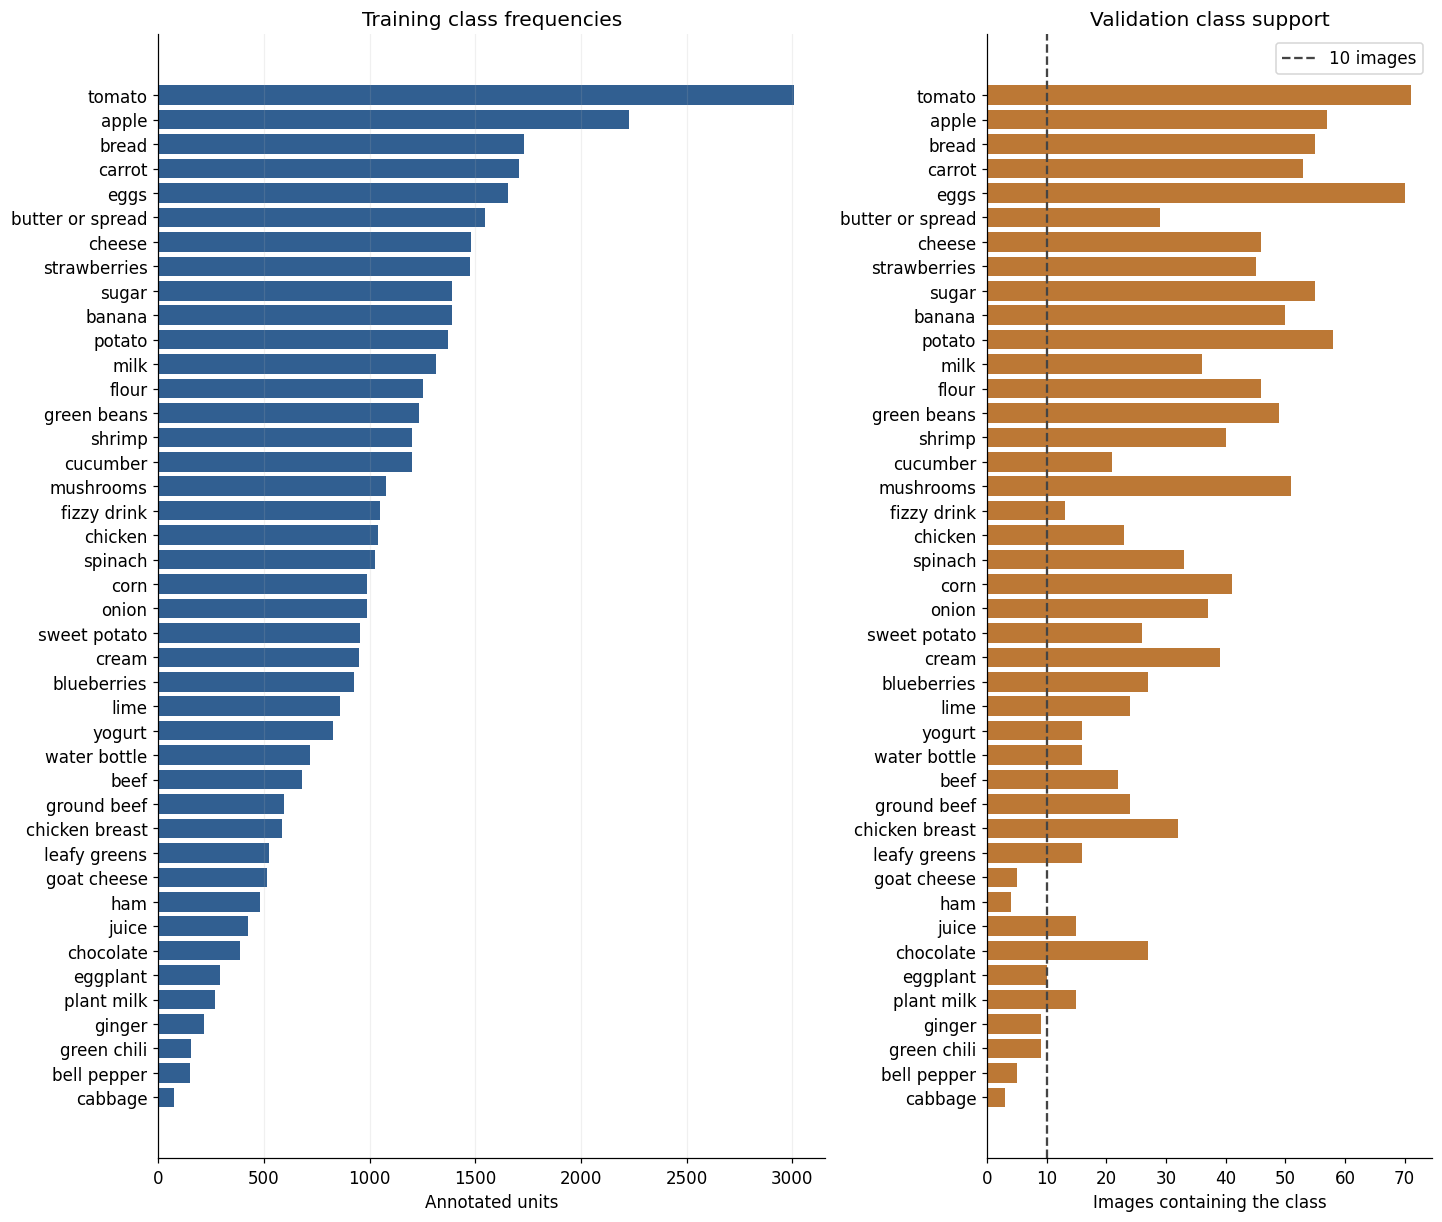

split,train,valid,test
dataset_name,,,
AIcook,2367,94,50
Fridge Food Images,940,64,35
Smart Fridge,665,16,12


,class_name,images,objects
export_class_id,,,
31,cabbage,3,3
17,ham,4,4
14,goat_cheese,5,5
32,bell_pepper,5,8
34,ginger,9,14
35,green_chili,9,14


Training counts range from **75** to **3007** units per class. **6 validation classes** occur in fewer than ten images. Report this support alongside their results; do not remove rare classes.

In [ ]:
train_support = support[support.split == 'train'].set_index('export_class_id').sort_values('objects')
# Show validation support beside the training frequencies.
valid_support = support[support.split == 'valid'].set_index('export_class_id')
fig, axes = plt.subplots(1, 2, figsize=(13, 11), layout='constrained', gridspec_kw={'width_ratios': [1.5, 1]})
labels = [name.replace('_', ' ') for name in train_support.class_name]
axes[0].barh(labels, train_support.objects, color='#315f91')
axes[0].set(title='Training class frequencies', xlabel='Annotated units')
axes[0].grid(axis='x', alpha=.18)
axes[1].barh(labels, valid_support.loc[train_support.index, 'images'], color='#bc7835')
axes[1].set(title='Validation class support', xlabel='Images containing the class')
axes[1].axvline(10, color='#444444', linestyle='--', label='10 images')
axes[1].legend()
show_figure(fig, 'class_balance.png')
source_counts = eda_images.pivot_table(index='dataset_name', columns='split', values='image_id', aggfunc='size', fill_value=0).reindex(columns=SPLITS)
display(source_counts)
source_counts.to_csv(RUN_DIR / 'source_contributions.csv')
sparse = valid_support[valid_support.images < 10][['class_name', 'images', 'objects']].sort_values('images')
display(sparse)
display(Markdown(f'Training counts range from **{int(train_support.objects.min())}** to '
                 f'**{int(train_support.objects.max())}** units per class. '
                 f'**{len(sparse)} validation classes** occur in fewer than ten images. '
                 'Report this support alongside their results; do not remove rare classes.'))


### Box sizes and training examples

Box statistics use all training labels. Image dimensions use up to 300 seeded training images to keep this step quick. Normalized area is the fraction of the image covered by a box.

The preview includes a crowded scene, a reviewed negative and two ordinary examples. Existing images are preserved; no augmentation is added.

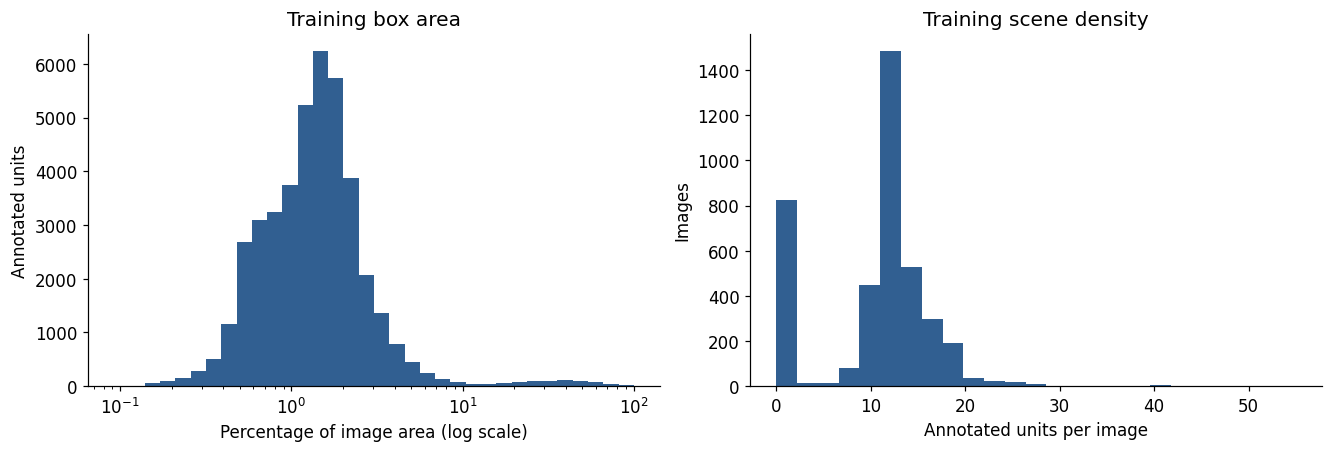

,width,height,aspect_ratio
count,300.0,300.0,300.0
mean,640.0,640.0,1.0
std,0.0,0.0,0.0
min,640.0,640.0,1.0
25%,640.0,640.0,1.0
50%,640.0,640.0,1.0
75%,640.0,640.0,1.0
max,640.0,640.0,1.0


Dimension sample: 300 images | square images: 300


,box_width,box_height,area,aspect_ratio
count,41957.0000,41957.0000,41957.0000,41957.0000
mean,0.1694,0.1041,0.0220,2.0190
std,0.0920,0.0852,0.0548,1.2319
min,0.0141,0.0064,0.0009,0.1163
25%,0.1172,0.0641,0.0085,1.2441
50%,0.1531,0.0844,0.0137,1.8116
75%,0.2000,0.1141,0.0195,2.4839
max,1.0000,1.0000,1.0000,39.2251


The median labelled unit occupies **1.37%** of its image. The median training image contains **12** units; the most crowded contains **55**. These annotation units can cover packages and batches, so piece-by-piece detections may disagree with the reviewed boxes.

In [ ]:
training_images = eda_images[eda_images.split == 'train']
training_boxes = eda_boxes[eda_boxes.split == 'train'].copy()
training_boxes['area'] = training_boxes.box_width * training_boxes.box_height
training_boxes['aspect_ratio'] = training_boxes.box_width / training_boxes.box_height
# Sample image dimensions to avoid opening every training image.
sample = training_images.sample(min(CONFIG['geometry_sample_images'], len(training_images)), random_state=CONFIG['seed'])
dimensions = []
for row in sample.itertuples():
    with Image.open(DATASET_ROOT / row.image_path) as photo:
        width, height = photo.size
    dimensions.append({'width': width, 'height': height, 'aspect_ratio': width / height})
dimension_table = pd.DataFrame(dimensions)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
area_percent = 100 * training_boxes.area
area_bins = np.geomspace(area_percent.min(), area_percent.max(), 35)
axes[0].hist(area_percent, bins=area_bins, color='#315f91')
axes[0].set(xscale='log', title='Training box area', xlabel='Percentage of image area (log scale)', ylabel='Annotated units')
axes[1].hist(training_images.objects, bins=25, color='#315f91')
axes[1].set(title='Training scene density', xlabel='Annotated units per image', ylabel='Images')
show_figure(fig, 'training_geometry.png')
display(dimension_table.describe().round(2))
print('Dimension sample:', len(sample), 'images | square images:', int((dimension_table.width == dimension_table.height).sum()))
display(training_boxes[['box_width', 'box_height', 'area', 'aspect_ratio']].describe().round(4))
display(Markdown(f'The median labelled unit occupies **{100*training_boxes.area.median():.2f}%** of its image. '
                 f'The median training image contains **{training_images.objects.median():.0f}** units; '
                 f'the most crowded contains **{training_images.objects.max()}**. '
                 'These annotation units can cover packages and batches, so piece-by-piece detections may disagree with the reviewed boxes.'))


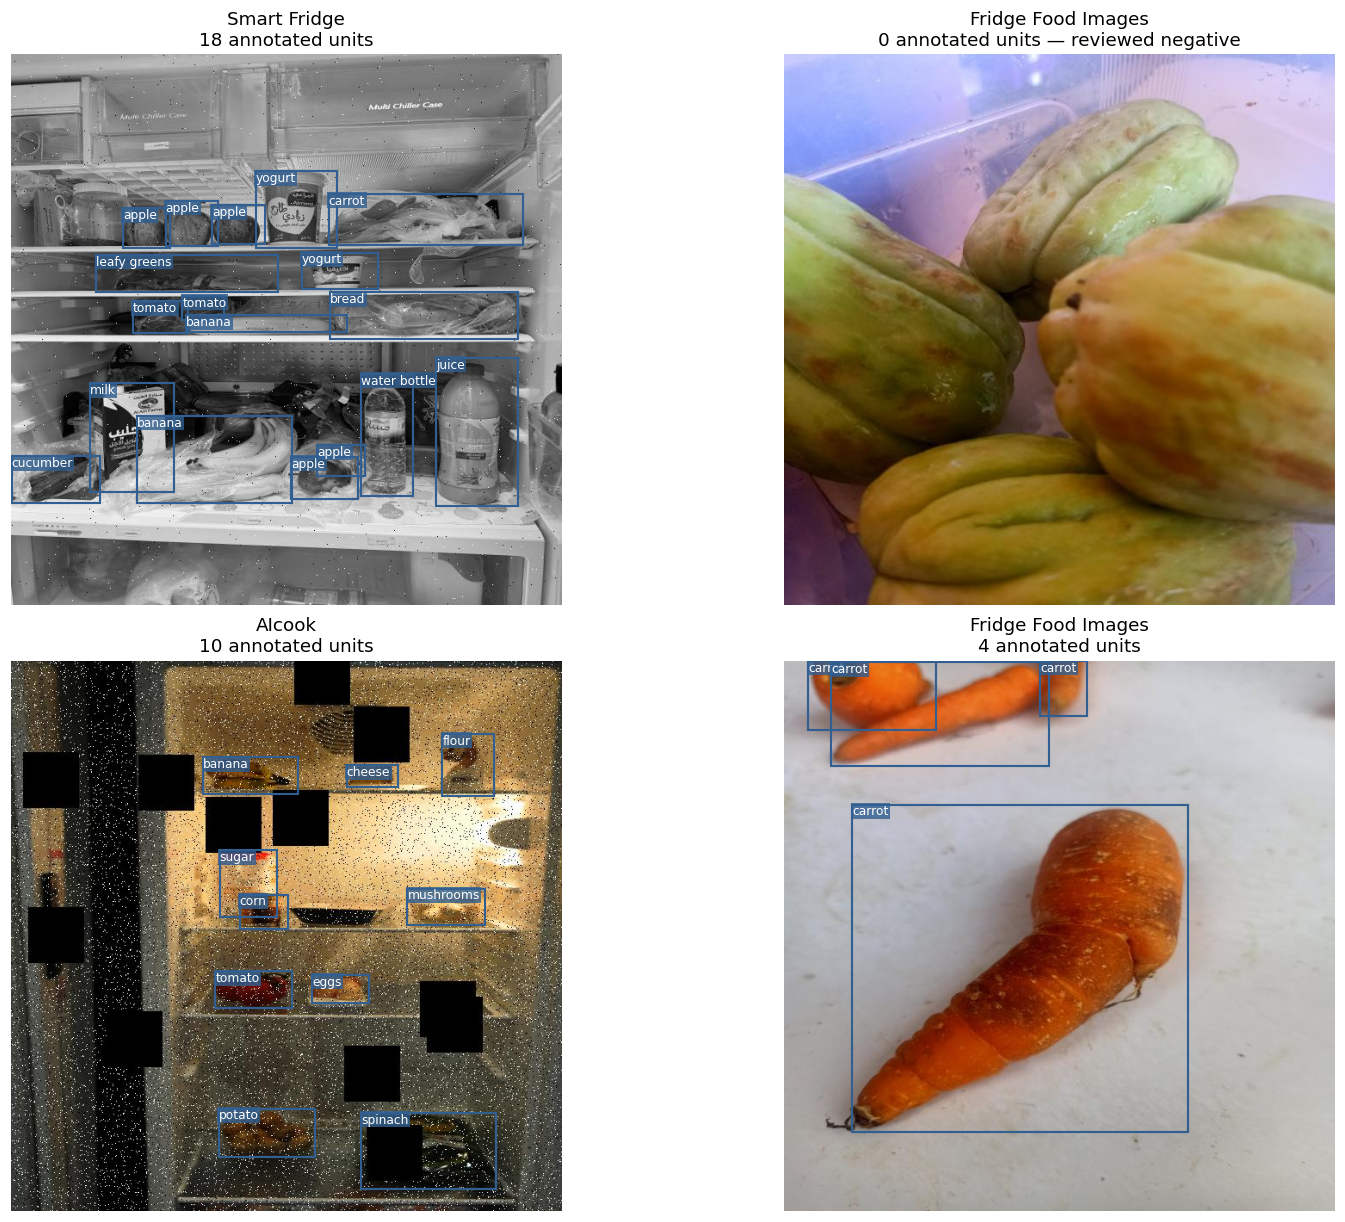

In [ ]:
def draw_boxes(axis, items, colour, scores=False):
    """Draw original-pixel boxes and readable labels on an existing image axis."""
    for item in items:
        x1, y1, x2, y2 = item['bbox_xyxy']
        axis.add_patch(patches.Rectangle((x1, y1), x2-x1, y2-y1, fill=False, edgecolor=colour, linewidth=1.4))
        label = CLASS_NAMES[item['class_id']].replace('_', ' ')
        if scores:
            label += f" {item['confidence']:.2f}"
        axis.text(x1, y1, label, fontsize=8, color='white', va='top', clip_on=True,
                  bbox={'facecolor': colour, 'alpha': .8, 'pad': 1, 'edgecolor': 'none'})


# Include a crowded scene and a negative image in the preview.
chosen = [training_images[training_images.objects.between(18, 25)].sample(1, random_state=CONFIG['seed']).iloc[0]]
chosen.append(training_images[training_images.negative].sample(1, random_state=CONFIG['seed']).iloc[0])
chosen.extend(training_images[(training_images.objects.between(4, 10))].sample(2, random_state=CONFIG['seed']).iloc[i] for i in range(2))
fig, axes = plt.subplots(2, 2, figsize=(14, 11), layout='constrained')
for axis, row in zip(axes.flat, chosen):
    with Image.open(DATASET_ROOT / row.image_path) as source:
        photo = source.convert('RGB')
    width, height = photo.size
    items = [{'class_id': int(b.class_id), 'bbox_xyxy': [(b.center_x-b.box_width/2)*width,
              (b.center_y-b.box_height/2)*height, (b.center_x+b.box_width/2)*width,
              (b.center_y+b.box_height/2)*height]} for b in eda_boxes[eda_boxes.image_id == row.image_id].itertuples()]
    axis.imshow(photo)
    draw_boxes(axis, items, '#315f91')
    axis.set_title(f'{row.dataset_name}\n{row.objects} annotated units' + (' — reviewed negative' if row.negative else ''), fontsize=12)
    axis.axis('off')
show_figure(fig, 'training_examples.png')


## 5. Load the trained models

The checkpoint checks confirm the dataset and class order. RF-DETR is selected automatically only when one matching full run exists; otherwise, set its path in CONFIG.

YOLO11s uses 640-pixel inputs and RF-DETR uses 512-pixel inputs. Checkpoint fingerprints and inference settings keep saved predictions tied to the correct model.

In [ ]:
COMPONENTS = ['yolo', 'rfdetr']
METHOD_NAMES = {'yolo': 'YOLO11s', 'rfdetr': 'RF-DETR Small', 'ensemble': 'YOLO11s + RF-DETR (WBF)'}
CHECKPOINTS, CHECKPOINT_HASHES, COMPONENT_SETTINGS, COMPONENT_IDS, MODELS = {}, {}, {}, {}, {}
GPU_NAME = None


def validate_rf_checkpoint(path):
    """Verify that a native inference checkpoint belongs to a matching full-data run."""
    path = Path(path).expanduser()
    assert path.is_file(), f'Checkpoint not found: {path}'
    assert path.parent.name == 'native' and path.name in {'checkpoint_best_total.pth', 'checkpoint_best_regular.pth'}
    run = json.loads((path.parent.parent / 'run_config.json').read_text())
    native = json.loads((path.parent / 'training_config.json').read_text())
    # Reject smoke checkpoints and mismatched dataset records.
    assert run['config']['mode'] == 'full-training', 'Smoke checkpoints are excluded.'
    assert run['dataset_id'] == native['dataset_id'] == DATASET_ID
    assert run['class_names'] == native['class_names'] == CLASS_NAMES
    return path


def discover_rf_checkpoint():
    """Use the configured full checkpoint or require exactly one eligible recorded run."""
    if CONFIG['rfdetr_checkpoint']:
        return validate_rf_checkpoint(CONFIG['rfdetr_checkpoint'])
    candidates = []
    for folder in sorted(Path(CONFIG['rfdetr_run_root']).glob('*/native')):
        preferred = folder / 'checkpoint_best_total.pth'
        if not preferred.is_file():
            preferred = folder / 'checkpoint_best_regular.pth'
        if not preferred.is_file():
            continue
        try:
            candidates.append(validate_rf_checkpoint(preferred))
        except (AssertionError, FileNotFoundError, KeyError, json.JSONDecodeError) as error:
            print('Excluded incompatible RF-DETR run:', folder, '|', error)
    if len(candidates) != 1:
        display(pd.DataFrame({'eligible_rfdetr_checkpoint': [str(p) for p in candidates]}))
        raise ValueError('Set rfdetr_checkpoint to the intended full-run native checkpoint in CONFIG, then rerun this cell.')
    return candidates[0]


if EFFECTIVE_MODE != 'preparation':
    import torch
    from ultralytics import YOLO
    from rfdetr import RFDETR
    from ensemble_boxes import weighted_boxes_fusion
    assert torch.cuda.is_available(), 'Select a GPU in Colab Runtime settings.'
    for package, setting in [('ultralytics', 'ultralytics_version'), ('rfdetr', 'rfdetr_version'),
                             ('ensemble-boxes', 'ensemble_boxes_version')]:
        assert VERSIONS[package] == CONFIG[setting], f'Restart the runtime after installing {package}.'
    GPU_NAME = torch.cuda.get_device_name(0)
    torch.manual_seed(CONFIG['seed'])
    torch.cuda.manual_seed_all(CONFIG['seed'])
    assert float((torch.tensor([2., 3.], device='cuda') ** 2).sum()) == 13.
    CHECKPOINTS['yolo'] = Path(CONFIG['yolo_checkpoint']).expanduser()
    assert CHECKPOINTS['yolo'].is_file(), f'The submitted YOLO checkpoint is missing: {CHECKPOINTS["yolo"]}'
    CHECKPOINTS['rfdetr'] = discover_rf_checkpoint()
    for key in COMPONENTS:
        CHECKPOINT_HASHES[key] = sha256_file(CHECKPOINTS[key])
        COMPONENT_SETTINGS[key] = {'model': METHOD_NAMES[key], 'checkpoint_sha256': CHECKPOINT_HASHES[key],
            'dataset_identity': DATASET_ID, 'class_names': CLASS_NAMES, 'device': 'cuda', 'gpu': GPU_NAME,
            'precision': 'float32', 'batch': 1, 'prediction_floor': CONFIG['prediction_floor'],
            'max_detections': CONFIG['max_detections'], 'versions': VERSIONS,
            'resolution': CONFIG['yolo_image_size'] if key == 'yolo' else CONFIG['rfdetr_image_size'],
            'postprocessing': {'rect': False, 'nms_iou': CONFIG['yolo_nms_iou'], 'agnostic_nms': False,
                               'augment': False, 'quantize': 32} if key == 'yolo' else {'native_num_select': CONFIG['max_detections']}}
        COMPONENT_IDS[key] = hashlib.sha256(json.dumps(COMPONENT_SETTINGS[key], sort_keys=True).encode()).hexdigest()
    save_json(RUN_DIR / 'component_settings.json', COMPONENT_SETTINGS)
    display(pd.DataFrame([{'model': METHOD_NAMES[k], 'checkpoint': str(CHECKPOINTS[k]), 'sha256': CHECKPOINT_HASHES[k]} for k in COMPONENTS]))
    print('CUDA calculation passed on', GPU_NAME)
else:
    print('Preparation only: no trained weights loaded and no GPU inference.')

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


,model,checkpoint,sha256
0,YOLO11s,/content/drive/MyDrive/ICT304/Fridge_YOLO_Weig...,45adc4c4fd599c8b6067b2a027b6cfc7afff0b41a452e0...
1,RF-DETR Small,/content/drive/MyDrive/ICT304/FridgeChef_RFDET...,d12077ddf84b74fa830282f864f16a446e81528dd41829...


CUDA calculation passed on NVIDIA RTX PRO 6000 Blackwell Server Edition


In [ ]:
def get_model(key):
    """Lazily load the selected trained model and verify its architecture and actual class mapping."""
    if key not in MODELS:
        if key == 'yolo':
            detector = YOLO(str(CHECKPOINTS[key]))
            assert detector.task == 'detect'
            assert [detector.names[i] for i in range(len(detector.names))] == CLASS_NAMES
            assert detector.model.yaml['nc'] == len(CLASS_NAMES)
            assert detector.model.yaml.get('scale') == 's'
            assert Path(detector.model.yaml.get('yaml_file', '')).stem in {'yolo11s', 'yolo11'}
            detector.to('cuda')
        else:
            detector = RFDETR.from_checkpoint(str(CHECKPOINTS[key]), device='cuda', compile=False)
            detector.model.model = detector.model.model.to(device='cuda', dtype=torch.float32).eval()
            assert detector.__class__.__name__ == 'RFDETRSmall'
            assert detector.class_names == CLASS_NAMES
            assert detector.model_config.num_classes == len(CLASS_NAMES)
            assert detector.model_config.resolution == CONFIG['rfdetr_image_size']
            assert detector.model.postprocess.num_select == CONFIG['max_detections']
        MODELS[key] = detector
    return MODELS[key]


def canonical_boxes(class_ids, scores, boxes, width, height, allow_background=False):
    """Validate canonical IDs and return clipped pixel boxes, skipping and counting unusable candidates."""
    assert len(class_ids) == len(scores) == len(boxes)
    detections = []
    audit = {'background_removed': 0, 'clipped_boxes': 0, 'zero_area_removed': 0, 'nonfinite_removed': 0}
    for raw_id, raw_score, raw_box in zip(class_ids, scores, boxes):
        assert np.isfinite(raw_id) and float(raw_id).is_integer()
        class_id = int(raw_id)
        if allow_background and class_id == len(CLASS_NAMES):
            audit['background_removed'] += 1
            continue
        assert 0 <= class_id < len(CLASS_NAMES), 'Unexpected class ID; do not remap the checkpoint.'
        box = np.asarray(raw_box, dtype=float)
        assert box.shape == (4,)
        if not np.isfinite(box).all() or not np.isfinite(raw_score):
            audit['nonfinite_removed'] += 1
            continue
        assert 0 <= raw_score <= 1
        assert box[2] >= box[0] and box[3] >= box[1], 'Reversed box coordinates.'
        clipped = np.clip(box, [0, 0, 0, 0], [width, height, width, height])
        audit['clipped_boxes'] += int(not np.array_equal(box, clipped))
        # Remove boxes that have no area after clipping.
        if clipped[2] <= clipped[0] or clipped[3] <= clipped[1]:
            audit['zero_area_removed'] += 1
            continue
        if float(raw_score) > CONFIG['prediction_floor']:
            detections.append({'class_id': class_id, 'class_name': CLASS_NAMES[class_id],
                               'confidence': float(raw_score), 'bbox_xyxy': clipped.tolist()})
    detections.sort(key=lambda item: -item['confidence'])
    return detections[:CONFIG['max_detections']], audit


def predict_component(key, path):
    """Predict one photograph on CUDA and return canonical detections, dimensions and elapsed seconds."""
    detector = get_model(key)
    torch.cuda.synchronize()
    started = time.perf_counter()
    with Image.open(path) as source:
        photo = source.convert('RGB')
    width, height = photo.size
    if key == 'yolo':
        result = detector.predict(source=photo, imgsz=CONFIG['yolo_image_size'], rect=False,
            conf=CONFIG['prediction_floor'], iou=CONFIG['yolo_nms_iou'], max_det=CONFIG['max_detections'],
            device=0, quantize=32, augment=False, agnostic_nms=False, verbose=False, save=False)[0]
        assert tuple(result.orig_shape) == (height, width)
        detections, audit = canonical_boxes(result.boxes.cls.cpu().numpy(), result.boxes.conf.cpu().numpy(),
                                            result.boxes.xyxy.cpu().numpy(), width, height)
    else:
        result = detector.predict(photo, threshold=CONFIG['prediction_floor'], include_source_image=False)
        shapes = result.data.get('source_shape')
        if shapes is not None and len(result.class_id):
            assert np.array_equal(shapes, np.tile([height, width], (len(result.class_id), 1)))
        names = result.data.get('class_name')
        if names is not None:
            for raw_id, name in zip(result.class_id, names):
                if int(raw_id) < len(CLASS_NAMES):
                    assert str(name) == CLASS_NAMES[int(raw_id)]
        detections, audit = canonical_boxes(result.class_id, result.confidence, result.xyxy, width, height, True)
    if audit['nonfinite_removed']:
        raise FloatingPointError(f'{key}: nonfinite prediction; inspect the model before scoring.')
    torch.cuda.synchronize()
    return detections, audit, width, height, time.perf_counter()-started


## 6. Evaluation and saved predictions

- **Precision:** how many predicted boxes are correct. **Recall:** how many labelled targets are found.
- **IoU:** intersection over union, a measure of box overlap. Matches require the same class, IoU of at least 0.50 and one prediction per target.
- **mAP50** summarises precision–recall at IoU 0.50; **mAP50–95** includes stricter overlaps. These are detection metrics.
- **Ingredient F1** balances precision and recall for unique ingredients per image; it ignores box location.

All methods share one evaluator and a 300-box cap. AP retains low scores; display thresholds are selected separately. Saved predictions include empty results, and scoring requires every image.

In [ ]:
def comparison_protocol():
    """Return the fixed image, box and metric rules used for all three methods."""
    return {'version': 'FridgeChef-ensemble-COCO-v1', 'class_names': CLASS_NAMES,
            'box_format': 'xyxy_original_image_pixels', 'component_candidate_floor': CONFIG['prediction_floor'],
            'component_rule': 'strictly greater than floor', 'ap_minimum_score': 0.0,
            'fusion_rule': 'retain positive fused scores without reapplying component floor',
            'maximum_detections': CONFIG['max_detections'], 'ap_IoU_thresholds': np.linspace(.5, .95, 10).tolist(),
            'ap_recall_points': 101, 'ap_average': 'macro over supported classes',
            'detection_matching': 'confidence-ordered same-class one-to-one', 'matching_IoU': CONFIG['match_iou'],
            'ingredient_matching': 'unique canonical classes per image; no IoU'}


def check_current_inference_settings():
    """Reject inference edits made without rebuilding the component identities."""
    for key in COMPONENTS:
        saved = COMPONENT_SETTINGS[key]
        expected_size = CONFIG['yolo_image_size'] if key == 'yolo' else CONFIG['rfdetr_image_size']
        assert saved['resolution'] == expected_size, 'Inference size changed; rerun from configuration.'
        assert saved['prediction_floor'] == CONFIG['prediction_floor'], 'Candidate floor changed; rerun from configuration.'
        assert saved['max_detections'] == CONFIG['max_detections']
    assert COMPONENT_SETTINGS['yolo']['postprocessing']['nms_iou'] == CONFIG['yolo_nms_iou'], 'NMS changed; rerun from configuration.'


def load_final_lock():
    """Check fixed validation settings before any test predictions can run."""
    assert EFFECTIVE_MODE == 'final-test' and CONFIG['final_test_enabled'] and CONFIG['settings_frozen']
    check_current_inference_settings()
    frozen = json.loads(Path(CONFIG['frozen_settings_path']).read_text())
    assert frozen['source'] == 'validation only'
    # Final testing must reuse the saved validation choices.
    assert frozen['dataset_identity'] == DATASET_ID
    assert set(frozen['component_settings']) == set(COMPONENT_SETTINGS)
    runtime_changes = {}
    for key in COMPONENTS:
        saved, current = frozen['component_settings'][key], COMPONENT_SETTINGS[key]
        # Hardware and library records describe the runtime, not validation choices.
        runtime_fields = {'gpu', 'versions'}
        saved_protocol = {name: value for name, value in saved.items() if name not in runtime_fields}
        current_protocol = {name: value for name, value in current.items() if name not in runtime_fields}
        assert saved_protocol == current_protocol, f'{key}: checkpoint or inference settings changed.'
        runtime_changes[key] = {name: {'recorded': saved.get(name), 'current': current.get(name)}
                                for name in sorted(runtime_fields) if saved.get(name) != current.get(name)}
    audit_path = RUN_DIR / 'runtime_compatibility.json'
    if any(runtime_changes.values()) and not audit_path.exists():
        print('Runtime differs from the recorded run. The fixed FP32 protocol is unchanged; numerical results and timing may vary.')
    save_json(audit_path, {'semantic_settings_match': True, 'runtime_differences': runtime_changes})
    assert frozen['protocol'] == comparison_protocol()
    assert frozen['fusion']['confidence_type'] == CONFIG['fusion_confidence_type']
    assert len(frozen['fusion']['weights']) == 2 and all(v > 0 for v in frozen['fusion']['weights'])
    assert 0 < frozen['fusion']['iou'] < 1
    assert set(frozen['thresholds']) == {'yolo', 'rfdetr', 'ensemble'}
    assert all(np.isfinite(v) and 0 < v < 1 for v in frozen['thresholds'].values())
    return frozen


def require_complete(records, split):
    """Reject missing, duplicate, foreign or malformed image records before scoring or fusion."""
    rows = eda_images[eda_images.split == split].set_index('image_id')
    assert len(records) == len(rows) and {r['image_id'] for r in records} == set(rows.index)
    for record in records:
        assert record['split'] == split and record['dataset_identity'] == DATASET_ID
        assert record['image_path'] == rows.loc[record['image_id'], 'image_path']
        width, height = record['width'], record['height']
        assert width > 0 and height > 0 and len(record['detections']) <= CONFIG['max_detections']
        for item in record['detections']:
            class_id = item['class_id']
            assert isinstance(class_id, int) and 0 <= class_id < len(CLASS_NAMES)
            assert item['class_name'] == CLASS_NAMES[class_id]
            assert np.isfinite(item['confidence']) and 0 <= item['confidence'] <= 1
            x1, y1, x2, y2 = item['bbox_xyxy']
            assert np.isfinite([x1, y1, x2, y2]).all()
            assert 0 <= x1 < x2 <= width and 0 <= y1 < y2 <= height

In [ ]:
def truth_for_predictions(records, boxes, class_names):
    """Convert the prepared normalized labels into pixel boxes for the exported images."""
    grouped_boxes = {name: frame for name, frame in boxes.groupby('image_id')}
    truth = {}
    for record in records:
        items = []
        for row in grouped_boxes.get(record['image_id'], boxes.iloc[0:0]).itertuples():
            assert row.split == record['split']
            box = [(row.center_x-row.box_width/2)*record['width'],
                   (row.center_y-row.box_height/2)*record['height'],
                   (row.center_x+row.box_width/2)*record['width'],
                   (row.center_y+row.box_height/2)*record['height']]
            items.append({'class_id': int(row.class_id), 'class_name': class_names[int(row.class_id)],
                          'bbox_xyxy': box})
        truth[record['image_id']] = items
    return truth

def box_iou(first, second):
    """Return the intersection area divided by the union area of two pixel boxes."""
    overlap = max(0, min(first[2], second[2])-max(first[0], second[0]))
    overlap *= max(0, min(first[3], second[3])-max(first[1], second[1]))
    union = ((first[2]-first[0])*(first[3]-first[1])
             + (second[2]-second[0])*(second[3]-second[1])-overlap)
    return overlap / union if union > 0 else 0.0

def match_one_image(record, targets, threshold, match_iou=0.5):
    """Return scored predictions, matched pairs, false predictions and missed target indices."""
    predictions = sorted([d for d in record['detections'] if d['confidence'] >= threshold],
                         key=lambda item: -item['confidence'])
    used_targets, matches, false_predictions = set(), [], []
    # Match confident predictions first without reusing a target.
    for prediction_index, prediction in enumerate(predictions):
        options = [(box_iou(prediction['bbox_xyxy'], target['bbox_xyxy']), target_index)
                   for target_index, target in enumerate(targets)
                   if target_index not in used_targets and target['class_id'] == prediction['class_id']]
        overlap, target_index = max(options, default=(0.0, -1))
        if target_index >= 0 and overlap >= match_iou:
            matches.append((prediction_index, target_index))
            used_targets.add(target_index)
        else:
            false_predictions.append(prediction_index)
    missed_targets = [index for index in range(len(targets)) if index not in used_targets]
    return predictions, matches, false_predictions, missed_targets


In [ ]:
def ingredient_scores(records, truth, threshold):
    """Score deduplicated ingredient lists across all images at a fixed confidence threshold."""
    true_positive = false_positive = missed = correct_empty = 0
    for record in records:
        # Count each ingredient once per photograph.
        expected = {target['class_id'] for target in truth[record['image_id']]}
        predicted = {item['class_id'] for item in record['detections'] if item['confidence'] >= threshold}
        true_positive += len(expected & predicted)
        false_positive += len(predicted - expected)
        missed += len(expected - predicted)
        correct_empty += int(not expected and not predicted)
    precision = true_positive / max(1, true_positive + false_positive)
    recall = true_positive / max(1, true_positive + missed)
    return {'confidence': float(threshold), 'precision': precision, 'recall': recall,
            'F1': 2*precision*recall/(precision+recall) if precision+recall else 0.0,
            'true_positive_ingredients': true_positive, 'false_positive_ingredients': false_positive,
            'missed_ingredients': missed, 'correct_empty_lists': correct_empty, 'images': len(records)}

def detection_scores(records, truth, threshold, class_names, match_iou=0.5):
    """Calculate per-class and pooled box precision and recall with one-to-one IoU matching."""
    counts = np.zeros((len(class_names), 3), dtype=int)
    for record in records:
        targets = truth[record['image_id']]
        predictions, matches, false_predictions, missed_targets = match_one_image(record, targets, threshold, match_iou)
        for prediction_index, _ in matches:
            counts[predictions[prediction_index]['class_id'], 0] += 1
        for prediction_index in false_predictions:
            counts[predictions[prediction_index]['class_id'], 1] += 1
        for target_index in missed_targets:
            counts[targets[target_index]['class_id'], 2] += 1
    table = pd.DataFrame(counts, columns=['TP', 'FP', 'FN']).rename_axis('class_id').reset_index()
    table['precision'] = table.TP / (table.TP + table.FP).clip(lower=1)
    table['recall'] = table.TP / (table.TP + table.FN).replace(0, np.nan)
    tp, fp, fn = counts.sum(axis=0)
    summary = {'confidence': float(threshold), 'matching_IoU': float(match_iou),
        'micro_precision': float(tp/max(1, tp+fp)), 'micro_recall': float(tp/max(1, tp+fn)),
        'true_positive_boxes': int(tp), 'false_positive_boxes': int(fp), 'missed_boxes': int(fn)}
    return summary, table


In [ ]:
def score_average_precision(records, truth, class_names, prediction_floor=0.001, max_detections=300):
    """Return overall and per-class COCO AP, including images that have no predictions."""
    from pycocotools.coco import COCO
    from pycocotools.cocoeval import COCOeval
    from contextlib import redirect_stdout
    from io import StringIO
    categories = [{'id': i, 'name': name} for i, name in enumerate(class_names)]
    images, annotations, predictions = [], [], []
    for image_number, record in enumerate(records, 1):
        images.append({'id': image_number, 'width': record['width'], 'height': record['height']})
        for target in truth[record['image_id']]:
            x1, y1, x2, y2 = target['bbox_xyxy']
            annotations.append({'id': len(annotations)+1, 'image_id': image_number,
                'category_id': target['class_id'], 'bbox': [x1, y1, x2-x1, y2-y1],
                'area': (x2-x1)*(y2-y1), 'iscrowd': 0})
        for prediction in record['detections']:
            if prediction['confidence'] <= prediction_floor:
                continue
            x1, y1, x2, y2 = prediction['bbox_xyxy']
            predictions.append({'id': len(predictions)+1, 'image_id': image_number,
                'category_id': prediction['class_id'], 'bbox': [x1, y1, x2-x1, y2-y1],
                'area': (x2-x1)*(y2-y1), 'iscrowd': 0, 'score': prediction['confidence']})
    # Building both objects explicitly also supports an entirely empty prediction list.
    with redirect_stdout(StringIO()):
        actual, detected = COCO(), COCO()
        actual.dataset = {'info': {}, 'images': images, 'categories': categories, 'annotations': annotations}
        detected.dataset = {'info': {}, 'images': images, 'categories': categories, 'annotations': predictions}
        actual.createIndex()
        detected.createIndex()
        evaluator = COCOeval(actual, detected, 'bbox')
        evaluator.params.imgIds = [image['id'] for image in images]
        evaluator.params.catIds = list(range(len(class_names)))
        evaluator.params.maxDets = [1, 10, max_detections]
        evaluator.params.iouThrs = np.linspace(.5, .95, 10)
        evaluator.params.recThrs = np.linspace(0, 1, 101)
        evaluator.evaluate()
        evaluator.accumulate()
    grid = evaluator.eval['precision'][:, :, :, 0, -1]
    # Exclude classes without evaluable support from the average.
    def available_mean(values):
        available = values[values >= 0]
        return float(available.mean()) if available.size else float('nan')
    per_class = pd.DataFrame([{'class_id': i, 'class_name': name,
        'AP50': available_mean(grid[0, :, i]), 'AP50_95': available_mean(grid[:, :, i])}
        for i, name in enumerate(class_names)])
    return {'mAP50': available_mean(grid[0]), 'mAP50_95': available_mean(grid)}, per_class


In [ ]:
def collect_component(key, split, deadline):
    """Read a compatible cache and predict only missing images, preserving explicit empty results."""
    check_current_inference_settings()
    if split == 'test':
        load_final_lock()
    rows = eda_images[eda_images.split == split].sort_values('image_id')
    cache_dir = OUTPUT_ROOT / 'prediction_cache' / key / COMPONENT_IDS[key]
    cache_dir.mkdir(parents=True, exist_ok=True)
    path = cache_dir / (split + '.jsonl')
    records = []
    if path.exists():
        lines = path.read_text().splitlines()
        for index, line in enumerate(lines):
            try:
                records.append(json.loads(line))
            except json.JSONDecodeError:
                if index != len(lines)-1:
                    raise
                print('Recovering the interrupted last cache line:', key)
                path.write_text(''.join(json.dumps(r)+'\n' for r in records))
        if records and not path.read_bytes().endswith(b'\n'):
            with path.open('a') as handle:
                handle.write('\n')
    completed = {r['image_id']: r for r in records}
    assert len(completed) == len(records) and set(completed).issubset(set(rows.image_id))
    for record in records:
        assert record['component_id'] == COMPONENT_IDS[key]
        assert record['checkpoint_sha256'] == CHECKPOINT_HASHES[key]
        assert record['dataset_identity'] == DATASET_ID and record['split'] == split
    # Continue only the images not already saved.
    missing = rows[~rows.image_id.isin(completed)]
    if len(missing):
        if time.perf_counter() >= deadline:
            return None
        warmup_path = DATASET_ROOT / eda_images[eda_images.split == 'valid'].sort_values('image_id').iloc[0].image_path
        predict_component(key, warmup_path)
    with path.open('a') as handle:
        with tqdm(total=len(rows), initial=len(records), desc=f'{METHOD_NAMES[key]} {split}', unit='image') as progress:
            for row in missing.itertuples():
                if time.perf_counter() >= deadline:
                    print('Prediction budget reached. Rerun Collect component predictions to continue the saved cache.')
                    return None
                detections, audit, width, height, elapsed = predict_component(key, DATASET_ROOT / row.image_path)
                record = {'schema_version': 1, 'image_id': str(row.image_id), 'split': split,
                    'image_path': str(row.image_path), 'source_dataset': str(row.dataset_name), 'width': width, 'height': height,
                    'model': METHOD_NAMES[key], 'checkpoint': str(CHECKPOINTS[key]),
                    'checkpoint_sha256': CHECKPOINT_HASHES[key], 'dataset_identity': DATASET_ID,
                    'component_id': COMPONENT_IDS[key], 'detections': detections, 'box_audit': audit,
                    'latency_seconds': elapsed}
                handle.write(json.dumps(record)+'\n')
                handle.flush()
                completed[row.image_id] = record
                progress.update(1)
    records = [completed[image_id] for image_id in rows.image_id]
    require_complete(records, split)
    return records


### Collect component predictions

The progress bars count images, not epochs. Each detector predicts only missing images and saves progress. Empty detections are valid results; missing records mean the run is incomplete. Rerunning this step reuses matching saved predictions.

In [ ]:
COMPONENT_RECORDS = None
ACTIVE_SPLIT = 'test' if EFFECTIVE_MODE == 'final-test' else 'valid'
if EFFECTIVE_MODE != 'preparation':
    if ACTIVE_SPLIT == 'test':
        load_final_lock()
    # Both detector passes share this prediction time budget.
    deadline = time.perf_counter() + 60 * CONFIG['prediction_budget_minutes']
    gathered = {}
    for key in COMPONENTS:
        gathered[key] = collect_component(key, ACTIVE_SPLIT, deadline)
        if gathered[key] is None:
            break
    if len(gathered) == 2 and all(value is not None for value in gathered.values()):
        COMPONENT_RECORDS = gathered
        for key, records in COMPONENT_RECORDS.items():
            folder = RUN_DIR / ACTIVE_SPLIT / key
            folder.mkdir(parents=True, exist_ok=True)
            (folder / 'predictions.jsonl').write_text(''.join(json.dumps(r)+'\n' for r in records))
            save_json(folder / 'prediction_protocol.json', comparison_protocol())
            audit = {name: sum(r['box_audit'][name] for r in records) for name in records[0]['box_audit']}
            audit['images_without_detections'] = sum(not r['detections'] for r in records)
            save_json(folder / 'prediction_box_audit.json', audit)
        print('Both complete:', {key: len(records) for key, records in COMPONENT_RECORDS.items()})
    else:
        print('Metrics are paused until both models have predicted every image.')
else:
    print('Component predictions await the trained checkpoints and a Colab CUDA runtime.')


YOLO11s test:   0%|          | 0/97 [00:00<?, ?image/s]

/usr/local/lib/python3.13/dist-packages/rfdetr/detr.py:740: FutureWarning: The `RFDETRBase` was deprecated since v1.7.0. It will be removed in v2.0.0.
  getattr(variant_obj, "__name__", symbol): variant_obj
/usr/local/lib/python3.13/dist-packages/rfdetr/detr.py:740: FutureWarning: The `RFDETRLargeDeprecated` was deprecated since v1.7.0. It will be removed in v2.0.0.
  getattr(variant_obj, "__name__", symbol): variant_obj
/usr/local/lib/python3.13/dist-packages/rfdetr/detr.py:740: FutureWarning: The `RFDETRSegPreview` was deprecated since v1.7.0. It will be removed in v2.0.0.
  getattr(variant_obj, "__name__", symbol): variant_obj
[2026-10-03 00:53:27] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-03 00:53:27] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is

RF-DETR Small test:   0%|          | 0/97 [00:00<?, ?image/s]

Both complete: {'yolo': 97, 'rfdetr': 97}


## 7. Weighted Boxes Fusion

WBF merges overlapping boxes only when their class matches. Box locations are averaged using confidence and model weights.

The selected confidence rule rewards support from both detectors. With equal weights, a detection supported by one model drops from 0.90 to 0.45. All positive fused scores remain available for AP; the ensemble selects its own display threshold.

In [ ]:
def fuse_image(first, second, fusion):
    """Fuse two aligned image records and return positive-scoring canonical pixel boxes."""
    for field in ['image_id', 'split', 'image_path', 'width', 'height', 'dataset_identity']:
        assert first[field] == second[field], f'Unaligned model records: {field}'
    # Fusion expects coordinates scaled to the image dimensions.
    scale = np.array([first['width'], first['height'], first['width'], first['height']], dtype=float)
    boxes_list, scores_list, labels_list = [], [], []
    for record in [first, second]:
        candidates = [d for d in record['detections'] if d['confidence'] > CONFIG['prediction_floor']]
        boxes_list.append([(np.array(d['bbox_xyxy']) / scale).tolist() for d in candidates])
        scores_list.append([d['confidence'] for d in candidates])
        labels_list.append([d['class_id'] for d in candidates])
    boxes, scores, labels = weighted_boxes_fusion(
        boxes_list, scores_list, labels_list, weights=fusion['weights'], iou_thr=fusion['iou'],
        skip_box_thr=CONFIG['prediction_floor'], conf_type=fusion['confidence_type'], allows_overflow=False)
    detections = []
    for box, score, label in zip(boxes, scores, labels):
        assert np.isfinite(score) and 0 <= score <= 1 and float(label).is_integer()
        class_id = int(label)
        assert 0 <= class_id < len(CLASS_NAMES)
        pixel_box = np.clip(np.asarray(box, dtype=float), 0, 1) * scale
        assert np.isfinite(pixel_box).all()
        if score > 0 and pixel_box[2] > pixel_box[0] and pixel_box[3] > pixel_box[1]:
            detections.append({'class_id': class_id, 'class_name': CLASS_NAMES[class_id],
                               'confidence': float(score), 'bbox_xyxy': pixel_box.tolist()})
    detections.sort(key=lambda item: -item['confidence'])
    return detections[:CONFIG['max_detections']]


def fuse_records(components, fusion):
    """Return one ensemble record for every image, rejecting missing model records."""
    first, second = components['yolo'], components['rfdetr']
    split = first[0]['split']
    require_complete(first, split)
    require_complete(second, split)
    second_by_id = {r['image_id']: r for r in second}
    identity = {'checkpoints': CHECKPOINT_HASHES, 'components': COMPONENT_IDS, 'fusion': fusion}
    ensemble_id = hashlib.sha256(json.dumps(identity, sort_keys=True).encode()).hexdigest()
    records = []
    for record in first:
        started = time.perf_counter()
        detections = fuse_image(record, second_by_id[record['image_id']], fusion)
        records.append({key: record[key] for key in ['schema_version', 'image_id', 'split', 'image_path', 'source_dataset',
                                                     'width', 'height', 'dataset_identity']})
        records[-1].update({'model': METHOD_NAMES['ensemble'], 'checkpoint': 'fusion of recorded component checkpoints',
                           'checkpoint_sha256': ensemble_id, 'component_checkpoint_sha256': CHECKPOINT_HASHES,
                           'fusion': fusion, 'detections': detections, 'fusion_seconds': time.perf_counter()-started})
    require_complete(records, split)
    return records


In [ ]:
def select_threshold(records, truth):
    """Choose a method's display threshold using validation ingredient-list F1."""
    assert {record['split'] for record in records} == {'valid'}
    table = pd.DataFrame([ingredient_scores(records, truth, t) for t in CONFIG['threshold_candidates']])
    selected = table.sort_values(['F1', 'confidence'], ascending=[False, False]).iloc[0]
    return float(selected.confidence), table


def evaluate_method(key, records, threshold, truth):
    """Calculate and save a method's complete-split metrics with the common evaluator."""
    split = records[0]['split']
    require_complete(records, split)
    # Keep low scores for AP instead of using the display threshold.
    ap, per_class = score_average_precision(records, truth, CLASS_NAMES, 0.0, CONFIG['max_detections'])
    detection, counts = detection_scores(records, truth, threshold, CLASS_NAMES, CONFIG['match_iou'])
    ingredients = ingredient_scores(records, truth, threshold)
    per_class = per_class.merge(counts, on='class_id', validate='one_to_one')
    class_support = support[support.split == split].rename(columns={'export_class_id': 'class_id'})
    per_class = per_class.merge(class_support[['class_id', 'images', 'objects', 'independent_dependency_groups']],
                                on='class_id', validate='one_to_one')
    per_class['support_note'] = np.where(per_class.images < 10, 'fewer than 10 images', '')
    folder = RUN_DIR / split / key
    folder.mkdir(parents=True, exist_ok=True)
    summary = {'model': METHOD_NAMES[key], 'split': split, 'images': len(records), **ap, **detection,
               'ingredient_precision': ingredients['precision'], 'ingredient_recall': ingredients['recall'],
               'ingredient_F1': ingredients['F1'], 'dataset_identity': DATASET_ID,
               'checkpoint_sha256': records[0]['checkpoint_sha256'], 'protocol': comparison_protocol()}
    save_json(folder / 'detection_metrics.json', summary)
    save_json(folder / 'ingredient_metrics.json', ingredients)
    save_json(folder / 'prediction_protocol.json', comparison_protocol())
    per_class.to_csv(folder / 'per_class_metrics.csv', index=False)
    (folder / 'predictions.jsonl').write_text(''.join(json.dumps(r)+'\n' for r in records))
    return summary, per_class


## 8. Select settings on validation

Choose the best of six fusion settings using validation mAP50–95. Each method selects its display threshold using ingredient F1.

The ensemble becomes the preferred method only if it beats the best single detector by at least 0.5 percentage points. This is a practical rule, not a significance test. Selection can make validation scores optimistic.

In [ ]:
METHOD_RECORDS = SELECTED_FUSION = THRESHOLDS = COMPARISON = TRUTH = FROZEN_PATH = None
PER_CLASS = {}
PREFERRED_METHOD = None
if COMPONENT_RECORDS is not None and EFFECTIVE_MODE == 'validation':
    TRUTH = truth_for_predictions(COMPONENT_RECORDS['yolo'], eda_boxes, CLASS_NAMES)
    search_rows = []
    best_score = -1.0
    best_records = None
    candidates = [(weights, overlap) for weights in CONFIG['fusion_weights'] for overlap in CONFIG['fusion_iou_candidates']]
    for weights, overlap in tqdm(candidates, desc='Fusion settings', unit='setting'):
        fusion = {'weights': weights, 'iou': overlap, 'confidence_type': CONFIG['fusion_confidence_type']}
        fused = fuse_records(COMPONENT_RECORDS, fusion)
        ap, _ = score_average_precision(fused, TRUTH, CLASS_NAMES, 0.0, CONFIG['max_detections'])
        search_rows.append({'yolo_weight': weights[0], 'rfdetr_weight': weights[1], 'fusion_iou': overlap, **ap})
        if ap['mAP50_95'] > best_score:
            best_score, SELECTED_FUSION, best_records = ap['mAP50_95'], fusion, fused
    search_table = pd.DataFrame(search_rows)
    search_table.to_csv(RUN_DIR / 'fusion_validation_search.csv', index=False)
    display(search_table.assign(mAP50_percent=100*search_table.mAP50, mAP50_95_percent=100*search_table.mAP50_95)
                         .drop(columns=['mAP50', 'mAP50_95']).round(3))
    METHOD_RECORDS = {**COMPONENT_RECORDS, 'ensemble': best_records}
    THRESHOLDS, summaries = {}, []
    for key, records in METHOD_RECORDS.items():
        THRESHOLDS[key], threshold_table = select_threshold(records, TRUTH)
        summary, PER_CLASS[key] = evaluate_method(key, records, THRESHOLDS[key], TRUTH)
        threshold_table.to_csv(RUN_DIR / 'valid' / key / 'validation_thresholds.csv', index=False)
        summaries.append({'method_key': key, **summary})
    COMPARISON = pd.DataFrame(summaries).set_index('method_key')
    best_single = COMPARISON.loc[COMPONENTS, 'mAP50_95'].idxmax()
    gain = float(COMPARISON.loc['ensemble', 'mAP50_95'] - COMPARISON.loc[best_single, 'mAP50_95'])
    PREFERRED_METHOD = 'ensemble' if gain >= CONFIG['minimum_ensemble_gain'] else best_single
    frozen = {'source': 'validation only', 'dataset_identity': DATASET_ID, 'component_settings': COMPONENT_SETTINGS,
              'protocol': comparison_protocol(), 'fusion': SELECTED_FUSION, 'thresholds': THRESHOLDS,
              'preferred_method': PREFERRED_METHOD, 'minimum_ensemble_gain': CONFIG['minimum_ensemble_gain'],
              'selection_rule': 'fusion maximizes validation mAP50-95; thresholds maximize per-method ingredient F1',
              'validation_gain_over_best_single': gain}
    # Save the chosen settings for a later fixed test evaluation.
    FROZEN_PATH = RUN_DIR / 'frozen_validation_settings.json'
    save_json(FROZEN_PATH, frozen)
    print('Selected fusion:', SELECTED_FUSION)
    print('Validation gain over best single model:', round(100*gain, 3), 'percentage points of mAP50–95')
    print('Provisional preferred method:', METHOD_NAMES[PREFERRED_METHOD])
    print('Frozen validation settings:', FROZEN_PATH)
elif EFFECTIVE_MODE == 'validation':
    print('Complete both component prediction passes before validation comparison.')
else:
    print('Validation selection is disabled in this mode.')


Validation selection is disabled in this mode.


## 9. Final test

The supplied configuration already points to the frozen validation choices. Keep both checkpoints, thresholds, fusion rules and inference settings unchanged. A different CUDA GPU is allowed and recorded; its timing and numerical results may differ.

All three methods use the same 97 test images. Do not tune from these results. The test set was evaluated earlier in the project.

In [ ]:
if COMPONENT_RECORDS is not None and EFFECTIVE_MODE == 'final-test':
    # Load saved choices without searching again on test images.
    locked = load_final_lock()
    SELECTED_FUSION, THRESHOLDS = locked['fusion'], locked['thresholds']
    PREFERRED_METHOD = locked['preferred_method']
    METHOD_RECORDS = {**COMPONENT_RECORDS, 'ensemble': fuse_records(COMPONENT_RECORDS, SELECTED_FUSION)}
    TRUTH = truth_for_predictions(COMPONENT_RECORDS['yolo'], eda_boxes, CLASS_NAMES)
    summaries = []
    for key, records in METHOD_RECORDS.items():
        summary, PER_CLASS[key] = evaluate_method(key, records, THRESHOLDS[key], TRUTH)
        summaries.append({'method_key': key, **summary})
    COMPARISON = pd.DataFrame(summaries).set_index('method_key')
    save_json(RUN_DIR / 'test/frozen_settings_used.json', locked)
    print('All three fixed methods evaluated. Validation-selected preference:', METHOD_NAMES[PREFERRED_METHOD])
else:
    print('Final testing has not run in this mode.')


All three fixed methods evaluated. Validation-selected preference: RF-DETR Small


## 10. Compare results

The table reports percentages for all three methods. AP uses low-scoring predictions; box and ingredient scores use each method's selected confidence threshold. Compare class scores with their image and object counts, especially for rare classes.

,model,split,images,Selected confidence,mAP50 (%),mAP50–95 (%),Box precision (%),Box recall (%),Ingredient precision (%),Ingredient recall (%),Ingredient F1 (%)
method_key,,,,,,,,,,,
yolo,YOLO11s,test,97,0.25,91.55,61.33,83.72,91.55,95.43,96.90,96.16
rfdetr,RF-DETR Small,test,97,0.30,94.02,62.18,89.43,93.21,96.67,97.29,96.98
ensemble,YOLO11s + RF-DETR (WBF),test,97,0.10,93.37,62.14,79.20,94.88,93.41,98.84,96.05


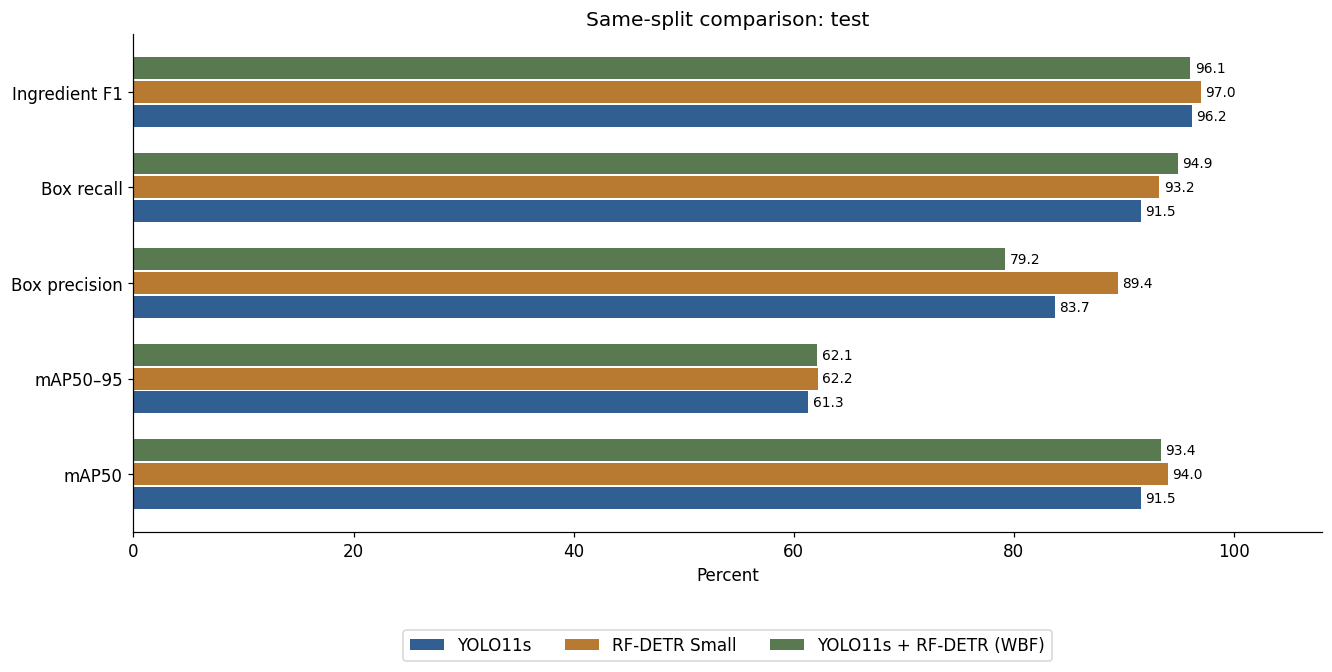

,class_name,images,objects,support_note,yolo_AP50_95_percent,rfdetr_AP50_95_percent,ensemble_AP50_95_percent,ensemble_gain_over_best_single_pp
0,apple,35,61,,54.33,52.04,53.01,-1.32
1,banana,17,20,,55.31,67.50,63.85,-3.65
2,beef,30,30,,31.01,28.14,29.74,-1.28
3,blueberries,23,23,,58.55,55.25,58.38,-0.17
4,bread,36,39,,64.09,62.73,63.91,-0.19
5,butter_or_spread,12,12,,77.90,76.92,79.41,1.51
6,carrot,25,33,,40.46,48.24,45.73,-2.51
7,cheese,29,29,,73.82,73.21,71.51,-2.32
8,chicken,32,32,,66.29,58.24,62.09,-4.20
9,chicken_breast,23,23,,36.19,39.37,37.29,-2.08


In [ ]:
if COMPARISON is not None:
    metric_columns = ['mAP50', 'mAP50_95', 'micro_precision', 'micro_recall', 'ingredient_F1']
    table_metrics = ['mAP50', 'mAP50_95', 'micro_precision', 'micro_recall',
                     'ingredient_precision', 'ingredient_recall', 'ingredient_F1']
    readable = COMPARISON[['model', 'split', 'images', 'confidence', *table_metrics]].copy()
    # Convert fractions to percentages for the comparison table.
    readable[table_metrics] *= 100
    readable = readable.rename(columns={'confidence': 'Selected confidence', 'mAP50': 'mAP50 (%)',
        'mAP50_95': 'mAP50–95 (%)', 'micro_precision': 'Box precision (%)',
        'micro_recall': 'Box recall (%)', 'ingredient_precision': 'Ingredient precision (%)',
        'ingredient_recall': 'Ingredient recall (%)', 'ingredient_F1': 'Ingredient F1 (%)'})
    display(readable.round(2))
    readable.to_csv(RUN_DIR / f'{ACTIVE_SPLIT}_comparison.csv', index=False)
    fig, axis = plt.subplots(figsize=(12, 6), layout='constrained')
    positions = np.arange(len(metric_columns))
    for offset, (key, colour) in enumerate([('yolo', '#315f91'), ('rfdetr', '#b87930'), ('ensemble', '#597950')]):
        bars = axis.barh(positions + (offset-1)*.25, 100*COMPARISON.loc[key, metric_columns].astype(float),
                         height=.23, color=colour, label=METHOD_NAMES[key])
        axis.bar_label(bars, fmt='%.1f', padding=3, fontsize=9)
    axis.set(yticks=positions, yticklabels=['mAP50', 'mAP50–95', 'Box precision', 'Box recall', 'Ingredient F1'],
             xlim=(0, 108), xlabel='Percent', title=f'Same-split comparison: {ACTIVE_SPLIT}')
    axis.legend(loc='upper center', bbox_to_anchor=(.5, -.18), ncol=3)
    show_figure(fig, f'{ACTIVE_SPLIT}_comparison.png')
    class_comparison = PER_CLASS['yolo'][['class_id', 'class_name', 'images', 'objects', 'support_note']].copy()
    for key in ['yolo', 'rfdetr', 'ensemble']:
        class_comparison[key + '_AP50_95_percent'] = 100*PER_CLASS[key].set_index('class_id').loc[class_comparison.class_id, 'AP50_95'].to_numpy()
    class_comparison['ensemble_gain_over_best_single_pp'] = class_comparison.ensemble_AP50_95_percent - class_comparison[['yolo_AP50_95_percent', 'rfdetr_AP50_95_percent']].max(axis=1)
    class_comparison.to_csv(RUN_DIR / f'{ACTIVE_SPLIT}_per_class_comparison.csv', index=False)
    with pd.option_context('display.max_rows', 50):
        display(class_comparison.drop(columns='class_id').round(2))
else:
    print('No complete comparison yet. No model metrics are invented.')


## 11. Measure prediction time

A small validation sample measures prediction time after warm-up. Timing waits for GPU work to finish and includes image loading and processing, but excludes model loading and plots.

Ensemble time adds both detector times and CPU fusion. It estimates sequential use. Set **benchmark_images** to **0** to skip this step.

In [ ]:
if METHOD_RECORDS is not None and CONFIG['benchmark_images'] > 0:
    timing_sample = eda_images[eda_images.split == 'valid'].sort_values('image_id').head(CONFIG['benchmark_images'])
    timing_records = {key: {} for key in COMPONENTS}
    timing_rows = []
    for key in COMPONENTS:
        predict_component(key, DATASET_ROOT / timing_sample.iloc[0].image_path)
        for row in tqdm(list(timing_sample.itertuples()), desc=f'{METHOD_NAMES[key]} timing', unit='image'):
            detections, _, width, height, elapsed = predict_component(key, DATASET_ROOT / row.image_path)
            timing_records[key][row.image_id] = {'image_id': row.image_id, 'split': 'valid', 'image_path': row.image_path,
                'width': width, 'height': height, 'dataset_identity': DATASET_ID, 'detections': detections, 'seconds': elapsed}
    for image_id in timing_sample.image_id:
        first, second = timing_records['yolo'][image_id], timing_records['rfdetr'][image_id]
        started = time.perf_counter()
        fuse_image(first, second, SELECTED_FUSION)
        fusion_seconds = time.perf_counter()-started
        # Add both detector times and fusion for sequential use.
        timing_rows.append({'image_id': image_id, 'yolo_ms': first['seconds']*1000,
            'rfdetr_ms': second['seconds']*1000, 'fusion_ms': fusion_seconds*1000,
            'ensemble_ms': (first['seconds']+second['seconds']+fusion_seconds)*1000})
    timings = pd.DataFrame(timing_rows)
    timings.to_csv(RUN_DIR / 'timing_by_image.csv', index=False)
    timing_summary = pd.DataFrame([{'method': METHOD_NAMES[key], 'median_ms': timings[key+'_ms'].median(),
        'p90_ms': timings[key+'_ms'].quantile(.9), 'sample_images': len(timings), 'gpu': GPU_NAME,
        'precision': 'float32', 'batch': 1} for key in ['yolo', 'rfdetr', 'ensemble']])
    display(timing_summary.round(2))
    timing_summary.to_csv(RUN_DIR / 'timing_summary.csv', index=False)
    save_json(RUN_DIR / 'timing_method.json', {'split': 'valid', 'warmups_per_component': 1,
        'includes': 'file reading, preprocessing, forward pass and postprocessing; CUDA synchronized',
        'excludes': 'model loading, prediction cache reads, plotting',
        'ensemble_method': 'sum of measured component and fusion times per image',
        'yolo_size': CONFIG['yolo_image_size'], 'rfdetr_size': CONFIG['rfdetr_image_size']})
else:
    print('Timing skipped until a complete comparison is available, or disabled in CONFIG.')


YOLO11s timing:   0%|          | 0/10 [00:00<?, ?image/s]

RF-DETR Small timing:   0%|          | 0/10 [00:00<?, ?image/s]

,method,median_ms,p90_ms,sample_images,gpu,precision,batch
0,YOLO11s,4.80,5.14,10,NVIDIA RTX PRO 6000 Blackwell Server Edition,float32,1
1,RF-DETR Small,15.40,15.65,10,NVIDIA RTX PRO 6000 Blackwell Server Edition,float32,1
2,YOLO11s + RF-DETR (WBF),28.02,29.54,10,NVIDIA RTX PRO 6000 Blackwell Server Edition,float32,1


## 12. Photograph demonstration

Show one photograph with YOLO11s, RF-DETR and fused boxes. Each uses its selected threshold. The default is a validation image; set **demo_image** to a supplied photograph's path to change it.

The ensemble ingredient list removes repeated class names, even when a single detector is preferred. Detections do not establish quantity, freshness or expiry.

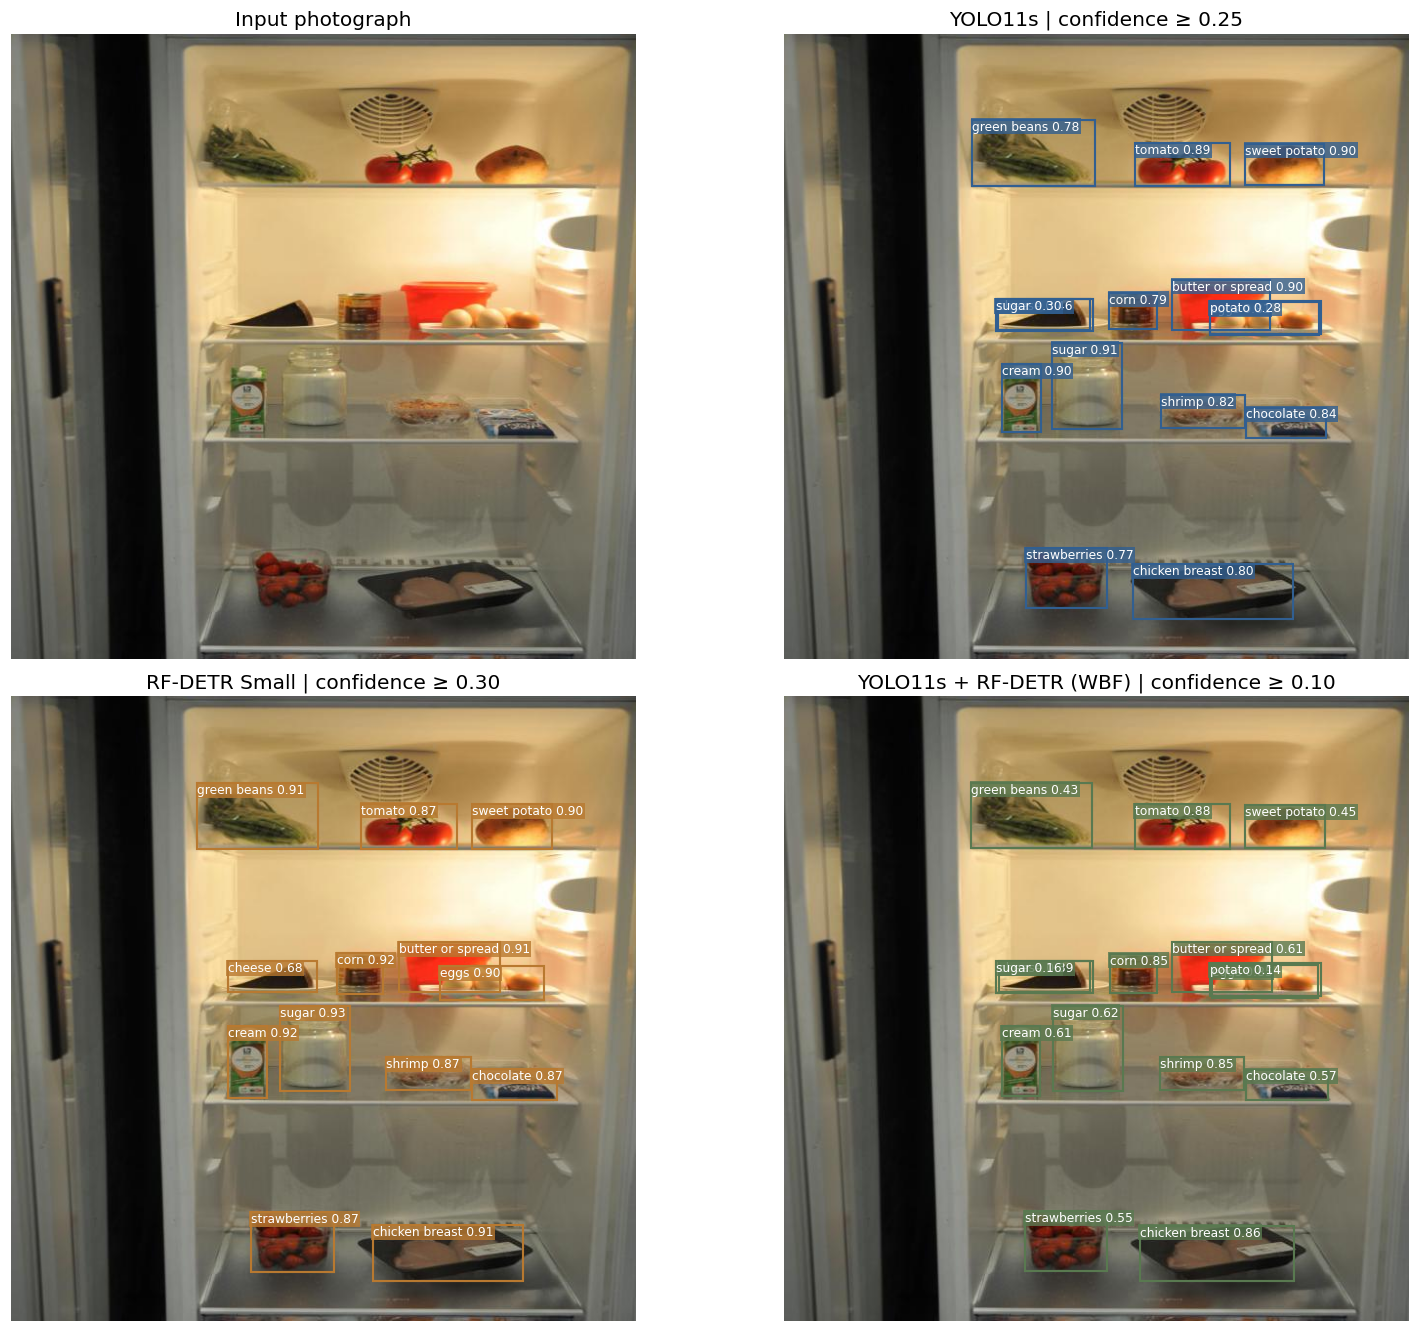

,class_id,class_name,display_name,confidence
0,5,butter_or_spread,butter or spread,0.608437
1,7,cheese,cheese,0.389901
2,9,chicken_breast,chicken breast,0.855086
3,10,chocolate,chocolate,0.573496
4,11,corn,corn,0.851040
5,12,eggs,eggs,0.851737
6,15,green_beans,green beans,0.429170
7,18,cream,cream,0.611114
8,23,potato,potato,0.140498
9,24,shrimp,shrimp,0.845754


In [ ]:
def unique_ingredients(detections, threshold):
    """Return one entry for each supported ingredient above a display threshold."""
    strongest = {}
    for item in detections:
        if item['confidence'] >= threshold:
            class_id = item['class_id']
            # Retain the strongest score for repeated ingredients.
            strongest[class_id] = max(strongest.get(class_id, 0), item['confidence'])
    return [{'class_id': class_id, 'class_name': CLASS_NAMES[class_id],
             'display_name': CLASS_NAMES[class_id].replace('_', ' '), 'confidence': strongest[class_id]}
            for class_id in sorted(strongest)]


if METHOD_RECORDS is not None:
    example = eda_images[(eda_images.split == 'valid') & (eda_images.objects > 0)].sort_values('image_id').iloc[0]
    demo_path = Path(CONFIG['demo_image']) if CONFIG['demo_image'] else DATASET_ROOT / example.image_path
    test_paths = {(DATASET_ROOT / p).resolve() for p in eda_images[eda_images.split == 'test'].image_path}
    assert demo_path.resolve() not in test_paths, 'Use a supplied or validation photograph for this demonstration.'
    if not CONFIG['demo_image'] and ACTIVE_SPLIT == 'valid':
        demo_records = {key: next(r for r in records if r['image_id'] == example.image_id) for key, records in METHOD_RECORDS.items()}
    else:
        demo_records = {}
        for key in COMPONENTS:
            detections, _, width, height, _ = predict_component(key, demo_path)
            demo_records[key] = {'image_id': 'supplied-demo', 'split': 'demo', 'image_path': str(demo_path),
                'width': width, 'height': height, 'dataset_identity': DATASET_ID, 'detections': detections}
        demo_records['ensemble'] = {'detections': fuse_image(demo_records['yolo'], demo_records['rfdetr'], SELECTED_FUSION)}
    with Image.open(demo_path) as source:
        photo = source.convert('RGB')
    fig, axes = plt.subplots(2, 2, figsize=(14, 12), layout='constrained')
    for axis in axes.flat:
        axis.imshow(photo)
        axis.axis('off')
    axes[0, 0].set_title('Input photograph')
    for axis, key, colour in zip(list(axes.flat)[1:], ['yolo', 'rfdetr', 'ensemble'], ['#315f91', '#b87930', '#597950']):
        visible = [d for d in demo_records[key]['detections'] if d['confidence'] >= THRESHOLDS[key]]
        draw_boxes(axis, visible, colour, True)
        axis.set_title(f'{METHOD_NAMES[key]} | confidence ≥ {THRESHOLDS[key]:.2f}')
    show_figure(fig, 'ensemble_demonstration.png')
    ingredients = unique_ingredients(demo_records['ensemble']['detections'], THRESHOLDS['ensemble'])
    display(pd.DataFrame(ingredients, columns=['class_id', 'class_name', 'display_name', 'confidence']))
    save_json(RUN_DIR / 'ensemble_ingredients.json', {'image': str(demo_path), 'ingredients': ingredients,
        'confidence': THRESHOLDS['ensemble'], 'fusion': SELECTED_FUSION})
    if not ingredients:
        print('The ensemble detected no supported ingredients at the selected threshold.')
else:
    print('The photograph comparison appears after complete evaluation.')


## 13. Conclusions and references

In the saved final-test results, RF-DETR leads on both mAP metrics and ingredient F1. Fusion increases recall but lowers precision at the selected thresholds. Small class support limits confidence in per-class scores.

Save the executed notebook, settings, predictions and result files. Report measured results only; do not retune from test scores. Earlier YOLO11s and RF-DETR scores used different splits, so use this shared comparison.

The architectures and WBF are external work. Our contributions are dataset preparation, fine-tuning, comparison and ingredient processing.

**References**

- [WBF paper](https://arxiv.org/abs/1910.13302) and [author implementation](https://github.com/ZFTurbo/Weighted-Boxes-Fusion).
- Ultralytics [prediction](https://docs.ultralytics.com/modes/predict/) and [validation](https://docs.ultralytics.com/modes/val/) documentation.
- RF-DETR [detection guide](https://rfdetr.roboflow.com/latest/learn/run/detection/) and [API](https://rfdetr.roboflow.com/latest/reference/rfdetr/).
- [COCO detection evaluator](https://github.com/cocodataset/cocoapi/blob/master/PythonAPI/pycocotools/cocoeval.py).
- Project evidence: dataset README, registry, support, provenance and attribution; YOLO11s and RF-DETR notebooks.